# 05. 학습된 영상 분류기로 추론하기

04에서 저장한 체크포인트를 불러와 `test` split의 영상들로 추론해보고,
예측 확률을 막대그래프로 같이 보여준다.

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd()))

import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from torchvision.models.video import r3d_18

from video_utils import VideoClipDataset, denormalize_for_display

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
CKPT_PATH = Path("checkpoints/r3d18_ucf101_subset.pt")

ckpt = torch.load(CKPT_PATH, map_location=DEVICE)
CLASSES = ckpt["classes"]

model = r3d_18(weights=None)
model.fc = nn.Linear(model.fc.in_features, len(CLASSES))
model.load_state_dict(ckpt["model_state"])
model = model.to(DEVICE).eval()
print("불러온 클래스:", CLASSES)


불러온 클래스: ['ApplyEyeMakeup', 'ApplyLipstick', 'Archery', 'BabyCrawling', 'BalanceBeam', 'BandMarching', 'BaseballPitch', 'Basketball', 'BasketballDunk', 'BenchPress']


## 5-1. test split 준비

In [2]:
DATA_DIR = Path("data/UCF101_subset")
NUM_FRAMES, CLIP_SIZE = 16, 112
class_to_idx = {c: i for i, c in enumerate(CLASSES)}

test_paths, test_labels = [], []
for cls in CLASSES:
    for p in sorted((DATA_DIR / "test" / cls).glob("*.avi")):
        test_paths.append(p)
        test_labels.append(class_to_idx[cls])

test_ds = VideoClipDataset(test_paths, test_labels, NUM_FRAMES, CLIP_SIZE)
print(f"test 영상 수: {len(test_ds)}")


test 영상 수: 75


## 5-2. 한 개 샘플 추론 + 확률 시각화

/tmp/ipykernel_89104/1642114747.py:20: UserWarning: Glyph 51221 (\N{HANGUL SYLLABLE JEONG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_89104/1642114747.py:20: UserWarning: Glyph 45813 (\N{HANGUL SYLLABLE DAB}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_89104/1642114747.py:20: UserWarning: Glyph 50696 (\N{HANGUL SYLLABLE YE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_89104/1642114747.py:20: UserWarning: Glyph 52769 (\N{HANGUL SYLLABLE CEUG}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_89104/1642114747.py:20: UserWarning: Glyph 53364 (\N{HANGUL SYLLABLE KEUL}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_89104/1642114747.py:20: UserWarning: Glyph 47000 (\N{HANGUL SYLLABLE RAE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_89104/1642114747.py:20: UserWarning: Glyph 49828 (\N{HANGUL SYLLABLE SEU}) missing from font(s) DejaVu Sans.
  p

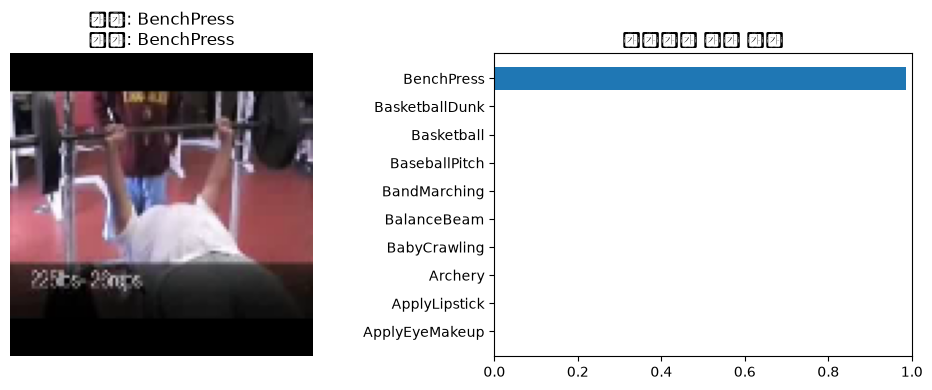

In [3]:
import random

idx = random.randrange(len(test_ds))
clip_tensor, true_label = test_ds[idx]

with torch.no_grad():
    logits = model(clip_tensor.unsqueeze(0).to(DEVICE))
    probs = torch.softmax(logits, dim=1)[0].cpu()

pred_label = probs.argmax().item()

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(denormalize_for_display(clip_tensor[:, 0]))
axes[0].set_title(f"정답: {CLASSES[true_label]}\n예측: {CLASSES[pred_label]}")
axes[0].axis("off")

axes[1].barh(CLASSES, probs.numpy())
axes[1].set_xlim(0, 1)
axes[1].set_title("클래스별 예측 확률")
plt.tight_layout()
plt.show()


## 5-3. test 전체에 대한 정확도

In [4]:
from torch.utils.data import DataLoader

test_loader = DataLoader(test_ds, batch_size=4, shuffle=False, num_workers=2)
correct, total = 0, 0
with torch.no_grad():
    for xb, yb in test_loader:
        out = model(xb.to(DEVICE))
        correct += (out.argmax(1).cpu() == yb).sum().item()
        total += xb.size(0)
print(f"test accuracy: {correct/total:.2f} ({correct}/{total})")


test accuracy: 0.99 (74/75)


## 다음 단계

여기까지가 "영상 데이터를 읽고, 사전학습 3D CNN을 파인튜닝해서 분류하는" 가장 기본적인
파이프라인이다. 다음으로 넘어갈 만한 방향:

- **클래스/데이터 수를 늘려서** 같은 파이프라인이 얼마나 더 잘 버티는지 보기
- **`mc3_18` / `r2plus1d_18`로 교체**해서 정확도·속도 비교해보기 (03 노트북 참고)
- 분류를 넘어서 **시간 순서가 중요한 문제(행동 구간 찾기, 다음 행동 예측 등)**로 확장하기 -
  요리 로봇 쪽으로 보면 YouCook2 같은 "요리 절차" 영상 데이터셋이 이 방향의 다음 스텝이 된다.
